In [196]:
%load_ext autoreload
%autoreload 2

from nntool.api import NNGraph
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import pickle
import cv2
import torch
import os
import copy
import onnxruntime as ort

import sys
sys.path.append("../../../yolox_people_detection/quantization")
from dataset_generators import CostomCOCODaset, get_annotations
sys.path.append("../../../yolox_people_detection")
from decoding_layer.decoding import decode_C_style

sys.path.append("../../../YOLOX")
from yolox.data.data_augment import preproc as preprocess
from yolox.utils import multiclass_nms, demo_postprocess, vis

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [225]:
sigmoid = lambda x: 1/(1 + np.exp(-x))

In [201]:
# Create an inference session using the ONNX model and specify execution providers
session = ort.InferenceSession("../../../ultralytics/runs/base-bee-working/weights/best_upd.onnx")

# Get the model inputs
model_inputs = session.get_inputs()

# Store the shape of the input for later use
input_shape = model_inputs[0].shape
input_shape

[1, 3, 256, 256]

In [55]:
model_inputs[0].name, session.get_outputs()[0].name

('images', 'output0')

In [204]:
[i.name for i in session.get_outputs()]

['output0', '/model.22/Split_output_1']

In [205]:
def preprocess(img_path, input_width, input_height, swap=(2, 0, 1)):
        """
        Preprocesses the input image before performing inference.

        Returns:
            image_data: Preprocessed image data ready for inference.
        """
        # Read the input image using OpenCV
        img = cv2.imread(img_path)

        # Get the height and width of the input image
        img_height, img_width = img.shape[:2]

        # Convert the image color space from BGR to RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Resize the image to match the input shape
        img = cv2.resize(img, (input_width, input_height))

        # Normalize the image data by dividing it by 255.0
        image_data = np.array(img) / 255.0

        # Transpose the image to have the channel dimension as the first dimension
        image_data = np.transpose(image_data, swap)  # Channel first

        # Expand the dimensions of the image data to match the expected input shape
        image_data = np.expand_dims(image_data, axis=0).astype(np.float32)

        # Return the preprocessed image data
        return image_data, img_height, img_width

In [206]:
class YOLOXCOCODaset(CostomCOCODaset):
    def __init__(
        self, 
        image_folder, 
        annotations, 
        input_size,
        max_size=500, 
        transpose_to_chw=True,
        input_channels=3,
        img_type = "rgb",
        enable_slicing=True
        ):

        self._img = None
        self._ratio = 1
        super().__init__(
            image_folder, annotations, input_size, max_size, transpose_to_chw,
            input_channels, img_type, enable_slicing
        )

    def __iter__(self):
        self._idx = 0
        return self

    def __next__(self):

        if self._idx >= self.max_idx:
            raise StopIteration()

        filename = self.annotations[self._idx]["file_name"]

        if self.img_type == "bayer":
            filename = filename.replace("jpg", "png")
        img_file = os.path.join(self.data_dir, filename)

        # read image as BGR
        if self.transpose_to_chw:
            swap = (2, 0, 1)
        else:
            swap = (0, 1, 2)

        image_data, img_height, img_width = preprocess(img_file, *self.input_size, swap)

        self._idx += 1
        return image_data

    def __len__(self):
        return self.max_idx

In [207]:
def clip_stats(stats, n_std):
    clipped_stats = copy.deepcopy(stats)
    if n_std:
        for layer, stat in stats.items():
            min_, max_ = stat['range_out'][0]['min'], stat['range_out'][0]['max']
            mean, std = stat['range_out'][0]['mean'], stat['range_out'][0]['std']
            clipped_stats[layer]['range_out'][0]['min'] = max(min_, mean - n_std * std)
            clipped_stats[layer]['range_out'][0]['max'] = min(max_, mean + n_std * std)
    return clipped_stats

In [291]:
G = NNGraph.load_graph("/host/ultralytics/runs/base-bee-working/weights/best_upd.onnx", load_quantization=False)
max_activ_size, total_params = G.total_memory_usage
ops = G.total_ops

print(f"{G.name}:")
print(f"\tMax Active Size:\t{max_activ_size} elements")
print(f"\tTotal # Parameters:\t{total_params} elements")
print(f"\tTotal # Operations:\t{ops / 1e6:.2f} MOps")



only align_corners is supported as coordinate_transformation_mode not asymmetric
_model_10_Resize - only round_prefer_ceil is supported for nearest mode not floor
only align_corners is supported as coordinate_transformation_mode not asymmetric
_model_13_Resize - only round_prefer_ceil is supported for nearest mode not floor


best_upd:
	Max Active Size:	786432 elements
	Total # Parameters:	730937 elements
	Total # Operations:	262.43 MOps


In [292]:
## fix the order of the last layer to match that in pytorch 
G[-1].fixed_order = True

G.adjust_order()
G.add_dimensions()
G.fusions('scaled_match_group')
G.fusions('expression_matcher')

In [293]:
# calculate statistics
annotations = get_annotations("../../../YOLOX/datasets/pg_coco/annotations/instances_bee_working.json", class_ids=np.arange(81))
quant_dataset = YOLOXCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/bee_working",
    annotations      = annotations,
    max_size         = 100,
    input_size       = (256, 256),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = False
)

Loading annotations for class person...
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


In [294]:
stats = G.collect_statistics(quant_dataset)
stats = clip_stats(stats, n_std = 3)

# with open("precalculated_stats_yolov8.pickle", "wb") as f:
#     pickle.dump(stats, f)

In [295]:
# with open("precalculated_stats_yolov8.pickle", "rb") as f:
#     stats = pickle.load(f)

In [296]:

G.quantize(
    stats,
    graph_options={
        'bits': 8,
        'quantized_dimension': 'channel',
        'use_ne16': True,
        'hwc': True,
    },
    # node_options=options
    node_options= {
        'output_1' : 
        {
            'scheme' : 'float', 
            'float_type': 'float32'
        },
        'output_2': 
        {
            'scheme' : 'float', 
            'float_type': 'float32'
        }
    },
)

In [297]:
# calculate statistics
quant_dataset = YOLOXCOCODaset(
    image_folder     = "../../../YOLOX/datasets/pg_coco/bee_working",
    annotations      = annotations,
    max_size         = 1,
    input_size       = (256, 256),
    transpose_to_chw = True,
    input_channels   = 3,
    img_type         = "rgb",
    enable_slicing   = False
)

In [298]:
sample = next(quant_dataset)
sample.shape

(1, 3, 256, 256)

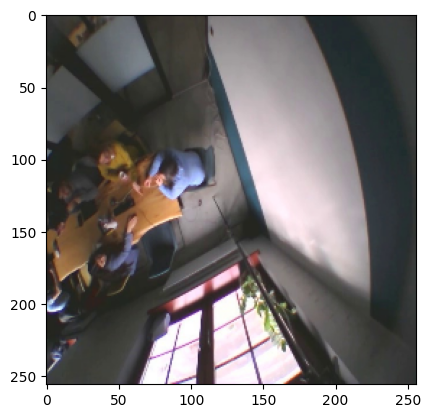

In [299]:
plt.imshow(np.transpose(sample[0] * 255, (1, 2, 0)).astype(np.uint8))

In [300]:
float_execution = G.execute(sample, quantize=False)

quant_execution = G.execute(sample, quantize=True, dequantize=True)

In [301]:
len(float_execution)

265

In [302]:
for i in float_execution:
    print(i[0].shape)

(256, 256, 3)
(16, 3, 3, 3)
(16,)
(128, 128, 16)
(24, 16, 3, 3)
(24,)
(64, 64, 24)
(24, 24, 1, 1)
(24,)
(64, 64, 24)
(64, 64, 12)
(64, 64, 12)
(12, 12, 3, 3)
(12,)
(64, 64, 12)
(12, 12, 3, 3)
(12,)
(64, 64, 12)
(64, 64, 12)
(64, 64, 36)
(24, 36, 1, 1)
(24,)
(64, 64, 24)
(40, 24, 3, 3)
(40,)
(32, 32, 40)
(40, 40, 1, 1)
(40,)
(32, 32, 40)
(32, 32, 20)
(32, 32, 20)
(20, 20, 3, 3)
(20,)
(32, 32, 20)
(20, 20, 3, 3)
(20,)
(32, 32, 20)
(32, 32, 20)
(32, 32, 60)
(40, 60, 1, 1)
(40,)
(32, 32, 40)
(32, 32, 40)
(72, 40, 3, 3)
(72,)
(16, 16, 72)
(72, 72, 1, 1)
(72,)
(16, 16, 72)
(16, 16, 36)
(16, 16, 36)
(36, 36, 3, 3)
(36,)
(16, 16, 36)
(36, 36, 3, 3)
(36,)
(16, 16, 36)
(16, 16, 36)
(16, 16, 108)
(72, 108, 1, 1)
(72,)
(16, 16, 72)
(72, 72, 3, 3)
(72,)
(8, 8, 72)
(72, 72, 1, 1)
(72,)
(8, 8, 72)
(8, 8, 36)
(8, 8, 36)
(36, 36, 3, 3)
(36,)
(8, 8, 36)
(36, 36, 3, 3)
(36,)
(8, 8, 36)
(8, 8, 36)
(8, 8, 108)
(72, 108, 1, 1)
(72,)
(8, 8, 72)
(36, 72, 1, 1)
(36,)
(8, 8, 36)
(8, 8, 36)
(8, 8, 36)
(8, 8, 36)

In [303]:
sigmoid(float_execution[-1][0])

array([[1.3600381e-01, 1.5282410e-01, 5.1926672e-02, ..., 1.2240454e-04,
        9.8812459e-05, 9.0125817e-05]], dtype=float32)

In [304]:
float_execution[-3]

[array([[7.6526947e+00, 8.8646736e+00, 1.9115486e+01, ..., 1.6772365e+02,
         1.9445071e+02, 2.3299352e+02],
        [7.8489494e+00, 5.8118601e+00, 4.5579400e+00, ..., 2.6130948e+02,
         2.4496780e+02, 2.5187158e+02],
        [1.4974613e+01, 1.5167100e+01, 2.1078033e+01, ..., 5.1365833e+02,
         4.9977350e+02, 4.8262906e+02],
        [1.5324833e+01, 1.1490746e+01, 8.8222189e+00, ..., 4.9193195e+02,
         5.1170026e+02, 5.0775983e+02],
        [1.3600381e-01, 1.5282410e-01, 5.1926672e-02, ..., 1.2240454e-04,
         9.8812459e-05, 9.0125817e-05]], dtype=float32)]

In [305]:
float_execution[-25][0]

array([[ 7.853838  ,  4.8490133 ,  5.501868  , ...,  0.94904184,
         1.1159292 ,  1.0990515 ],
       [ 7.6757646 ,  7.4916024 ,  5.9318175 , ...,  0.38252085,
         0.1153605 ,  0.47933924],
       [ 3.0026283 ,  6.9865704 ,  6.2820354 , ...,  0.794351  ,
         0.7452162 ,  1.026792  ],
       ...,
       [-0.52504945, -0.729529  , -0.8382789 , ...,  0.9845673 ,
         0.7646423 ,  1.0153843 ],
       [-0.86633873, -0.8441162 , -1.254787  , ...,  1.906096  ,
         1.6000774 ,  1.7723728 ],
       [-1.8488855 , -1.7126207 , -2.9045992 , ..., -9.008057  ,
        -9.222188  , -9.314214  ]], dtype=float32)

In [340]:
float_execution[-25][0][-1]

array([-1.8488855, -1.7126207, -2.9045992, ..., -9.008057 , -9.222188 ,
       -9.314214 ], dtype=float32)

In [341]:
float_execution[-1][0]

array([[-1.8488855, -1.7126207, -2.9045992, ..., -9.008057 , -9.222188 ,
        -9.314214 ]], dtype=float32)

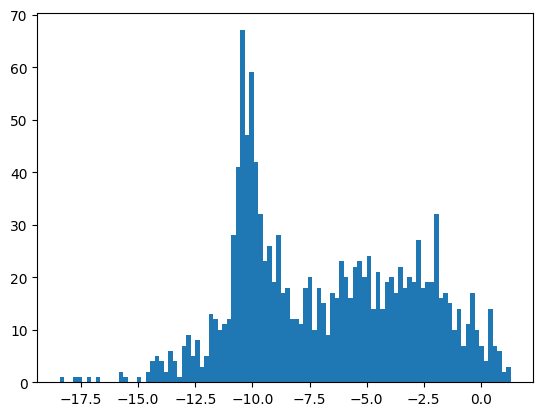

In [342]:
plt.hist(float_execution[-1][0].flatten(), bins=100);

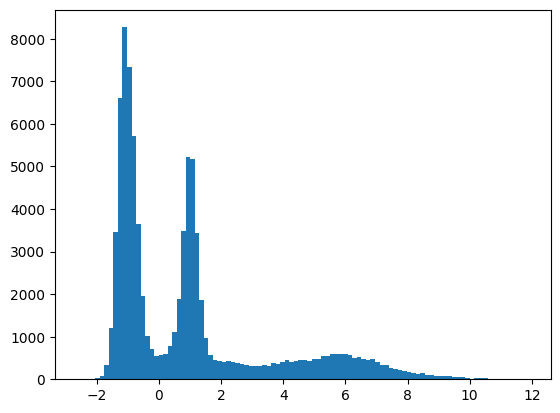

In [344]:
plt.hist(float_execution[-25][0][:-1].flatten(), bins=100);

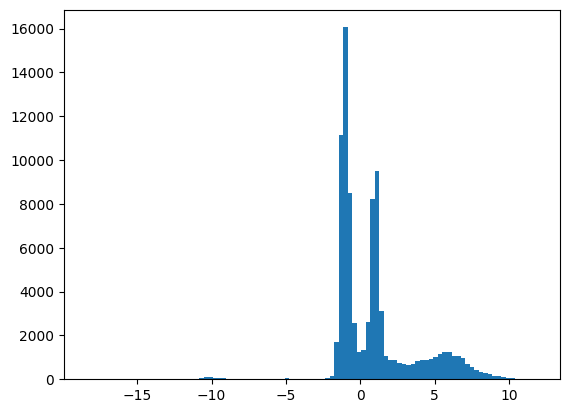

In [345]:
plt.hist(float_execution[-25][0].flatten(), bins=100);

In [350]:
quant_execution[-25][0][-1] - quant_execution[-1][0]

array([[ 2.61194566e-07,  1.60740871e-07,  4.20589074e-07, ...,
         1.17881626e-07,  1.17881626e-07, -8.43721271e-08]])

array([[-4.1607685, -6.7805114, -5.8558965, ..., -8.629742 , -8.629742 ,
        -8.783844 ]], dtype=float32)

In [306]:
float_execution[-1]

[array([[-1.8488855, -1.7126207, -2.9045992, ..., -9.008057 , -9.222188 ,
         -9.314214 ]], dtype=float32)]

In [307]:
quant_execution[-1][0]

array([[-4.1607685, -6.7805114, -5.8558965, ..., -8.629742 , -8.629742 ,
        -8.783844 ]], dtype=float32)

In [308]:
quant_execution[-20][0].shape

(4, 1344, 16)

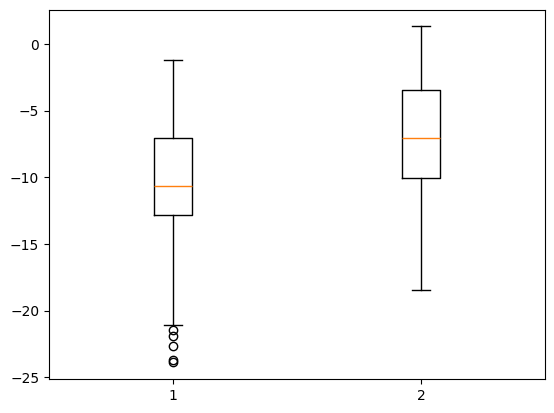

In [309]:
plt.boxplot((quant_execution[-1][0][0], float_execution[-1][0][0]));

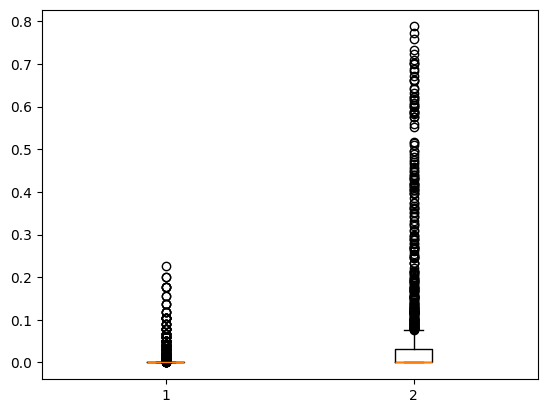

In [310]:
plt.boxplot((sigmoid(quant_execution[-1][0][0]), sigmoid(float_execution[-1][0][0])));

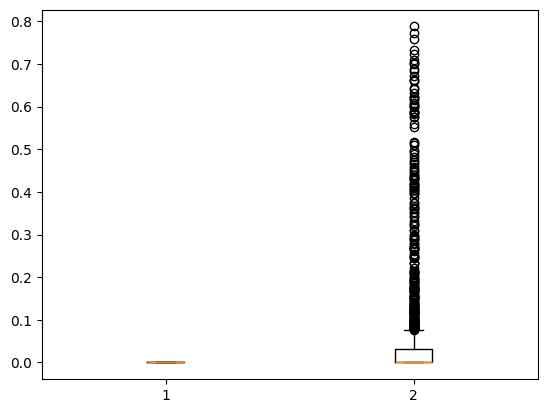

In [329]:
plt.boxplot((quant_execution[-3][0][-1], float_execution[-3][0][-1]));

In [326]:
float_execution[-3][0][-1]

array([1.3600381e-01, 1.5282410e-01, 5.1926672e-02, ..., 1.2240454e-04,
       9.8812459e-05, 9.0125817e-05], dtype=float32)

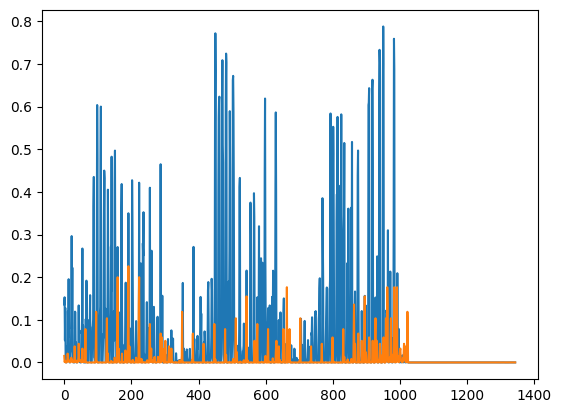

In [333]:
plt.plot(sigmoid(float_execution[-1][0][0]))
plt.plot(sigmoid(quant_execution[-1][0][0]))
# plt.plot(sigmoid(quant_execution[-1][0][0]) - sigmoid(float_execution[-1][0][0]))


In [52]:
float_execution = G.execute(sample, quantize=False)
quant_execution = G.execute(sample, quantize=True, dequantize=True)

In [53]:
from nntool.graph.types import ConstantInputNode
qsnrs_by_layer = G.qsnrs(float_execution, quant_execution)
print("QSNR layer by layer (skipping constant layers like weights and biases):")
print(f"{'Layer Name':>30} (  #): {'QSNR':4}")
for i, q in enumerate(qsnrs_by_layer):
    if isinstance(G[i], ConstantInputNode):
        continue
    print(f"{G[i].name:>30} ({i:3}): {q:4}")

QSNR layer by layer (skipping constant layers like weights and biases):
                    Layer Name (  #): QSNR
                       input_1 (  0):  147
     _model_0_conv_Conv_fusion (  3):    7
     _model_1_conv_Conv_fusion (  6):   10
 _model_2_cv1_conv_Conv_fusion (  9):   10
                _model_2_Split ( 10):    9
_model_2_m_0_cv1_conv_Conv_fusion_qin0 ( 11):   13
_model_2_m_0_cv1_conv_Conv_fusion ( 14):    7
    _model_2_m_0_cv2_conv_Conv ( 17):    6
                       expr_36 ( 18):    9
               _model_2_Concat ( 19):    9
 _model_2_cv2_conv_Conv_fusion ( 22):    9
     _model_3_conv_Conv_fusion ( 25):   10
 _model_4_cv1_conv_Conv_fusion ( 28):    9
                _model_4_Split ( 29):    9
_model_4_m_0_cv1_conv_Conv_fusion_qin0 ( 30):    9
_model_4_m_0_cv1_conv_Conv_fusion ( 33):  -13
    _model_4_m_0_cv2_conv_Conv ( 36):  -10
                       expr_41 ( 37):   -5
               _model_4_Concat ( 38):   -2
 _model_4_cv2_conv_Conv_fusion ( 41):    0
   

In [54]:
float_out = [float_execution[out_node.step_idx][0] for out_node in G.outputs()]
quant_out = [quant_execution[out_node.step_idx][0] for out_node in G.outputs()]

In [55]:
float_out[0].shape, quant_out[0].shape

((5, 1344), (5, 1344))

In [56]:
float_out[0]

array([[7.6526947e+00, 8.8646736e+00, 1.9115486e+01, ..., 1.6772365e+02,
        1.9445071e+02, 2.3299352e+02],
       [7.8489494e+00, 5.8118601e+00, 4.5579400e+00, ..., 2.6130948e+02,
        2.4496780e+02, 2.5187158e+02],
       [1.4974613e+01, 1.5167100e+01, 2.1078033e+01, ..., 5.1365833e+02,
        4.9977350e+02, 4.8262906e+02],
       [1.5324833e+01, 1.1490746e+01, 8.8222189e+00, ..., 4.9193195e+02,
        5.1170026e+02, 5.0775983e+02],
       [1.3600381e-01, 1.5282410e-01, 5.1926672e-02, ..., 1.2240454e-04,
        9.8812459e-05, 9.0125817e-05]], dtype=float32)

In [57]:
quant_out[0]

array([[ 13.080832,  19.621246,  26.161663, ..., 174.41109 , 209.2933  ,
        239.81525 ],
       [  4.360277,   4.360277,   4.360277, ..., 239.81525 , 239.81525 ,
        239.81525 ],
       [ 50.14319 ,  54.503464,  69.764435, ..., 475.2702  , 475.2702  ,
        475.2702  ],
       [ 34.882217,  34.882217,  34.882217, ..., 475.2702  , 475.2702  ,
        475.2702  ],
       [  0.      ,   0.      ,   0.      , ...,   0.      ,   0.      ,
          0.      ]], dtype=float32)

In [58]:
# On the target only fully integer values - NO DEQUANTIZE
int_execution = G.execute(sample, dequantize=False, quantize=True)

In [59]:
G[0].at_options.allocate = 1
G[0].at_options

{'ALLOCATE': 1}

In [60]:
work_dir = "/tmp/test_tutorial"
res = G.execute_on_target(
    pmsis_os='freertos',
    platform="gvsoc",
    directory=work_dir,
    input_tensors=int_execution[0],
    output_tensors=0,
    write_out_to_file=True,
    at_log=True,
    dont_run=False,
    do_clean=False,
    cmake=True,
    at_loglevel=2,
    print_output=True,
    settings={
        "l1_size": 128000,
        "l2_size": 1000000,

        "graph_monitor_cycles": True,
        "graph_produce_node_names": True,
        "graph_produce_operinfos": True,
        "graph_const_exec_from_flash": True,
    }
)

Script started, output log file is '/tmp/tmp_o_u133r/log.txt'.
-- [Custom BSP] Custom BSP unused.
-- [Python] Interpreter found here /usr/bin/python3.10
-- [Kconfig] KCONFIG_CONFIG environnement variable has not been exported.
-- [Kconfig] Using default value sdk: "sdk.config" and app: "sdk.config".
-- [NNTOOL] Using nntool in /gap_sdk_private/tools/nntool/scripts/nntool
-- [SFU] Using SFU in 
-- [DT] Formating configuration file
-- [DT] Selected options : gap9_v2_wlcsp;gap9mod_v1_0_b;gap9evk_v1_3
-- [DT] Compiling gap9_v2_wlcsp.dts
-- [DT] Compiling gap9mod_v1_0_b.dts
-- [DT] Compiling gap9evk_v1_3.dts
-- [DT] Dumping C header file
-- [Board] GAP Family : 9
-- [Board] GAP Version : 2
-- [AutoTiler] Using SQ8 kernels
-- [AutoTiler] Using FP16 kernels
-- [AutoTiler] Using NE16 kernels
-- [AutoTiler] Using Default Flash
-- [AutoTiler] Using Default RAM
-- [Compiler] Compiling for FreeRTOS on riscv32 using compiler found at /usr/lib/gap_riscv_toolchain/bin/riscv32-unknown-elf-gcc
-- [Auto

In [61]:
print(res.pretty_performance())

+-----------------------------------------------+------------+-------------+-----------+---------+----------+
| Layer                                         |   Cycles   |     Ops     | Ops/Cycle |  % ops  | % cycles |
+===============================================+============+=============+===========+=========+==========+
| S3__model_0_conv_Conv_fusion                  |  1,880,702 |   7,340,032 |     3.903 |   2.796 |   12.931 |
+-----------------------------------------------+------------+-------------+-----------+---------+----------+
| S6__model_1_conv_Conv_fusion                  |    685,855 |  14,254,080 |    20.783 |   5.429 |    4.716 |
+-----------------------------------------------+------------+-------------+-----------+---------+----------+
| S9__model_2_cv1_conv_Conv_fusion              |    482,627 |   2,457,600 |     5.092 |   0.936 |    3.318 |
+-----------------------------------------------+------------+-------------+-----------+---------+----------+
| S10__mod

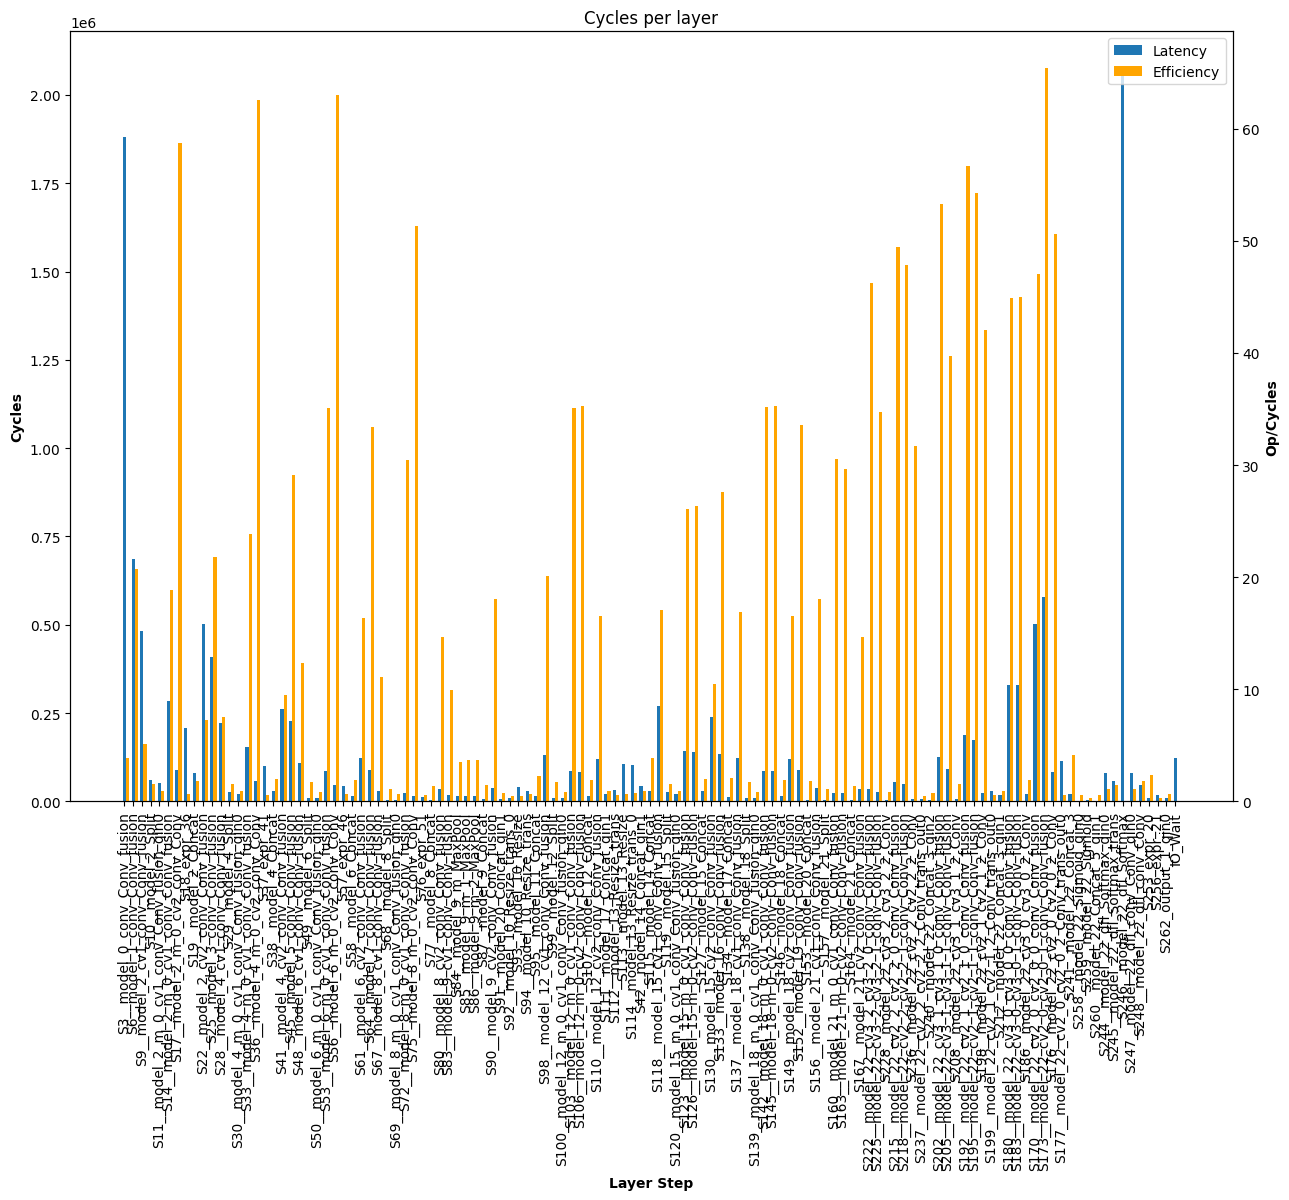

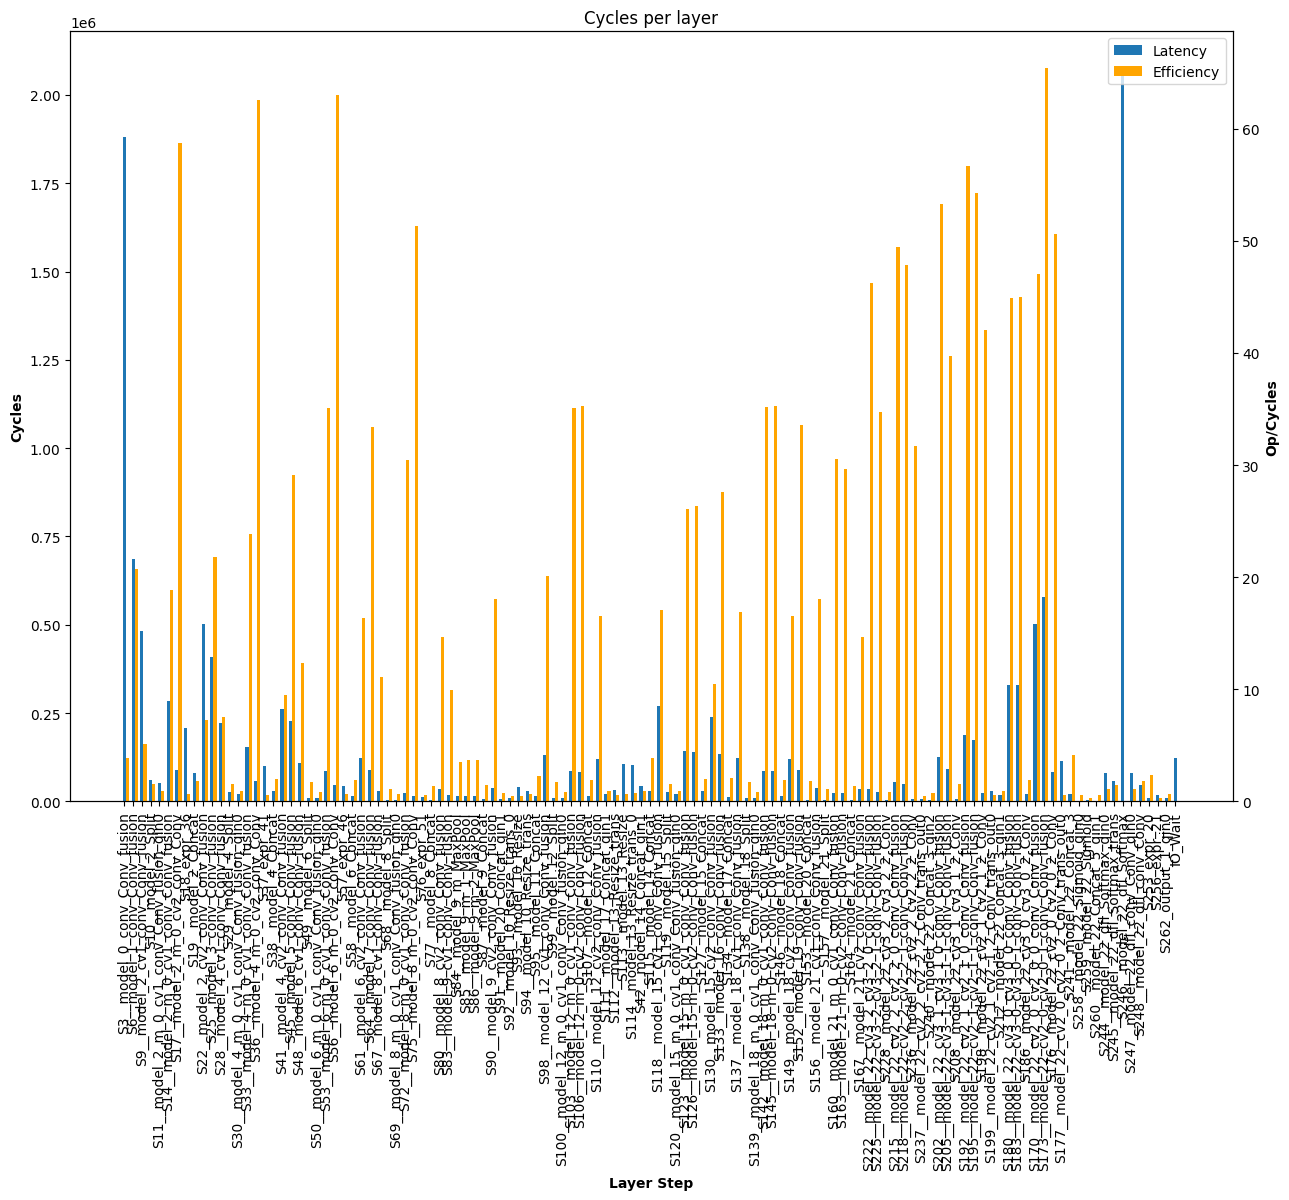

In [62]:
res.plot_performance()

In [63]:
res.basic_mem_infos

{'Max Alive Size': 461684,
 'Shared L1': {'given': 115712, 'used': 115688},
 'L2': {'given': 1000000, 'used': 1000000},
 'L2 Static Memory Usage': 541224,
 'L2 Dyn Memory Usage': 458776,
 'DefaultRam': {'given': 8000000, 'used': 0},
 'DefaultFlash': {'given': 67108864, 'used': 852992},
 'L3 Memory bandwidth for 1 graph run': 422177,
 'L2 Memory bandwidth for 1 graph run': 8645137,
 'Sum of all Kernels arguments size': 8482777}

No content found in the memory for this area L3


[<Figure size 1500x1000 with 1 Axes>,
 <Figure size 1500x1000 with 1 Axes>,
 <Figure size 1500x1000 with 1 Axes>]

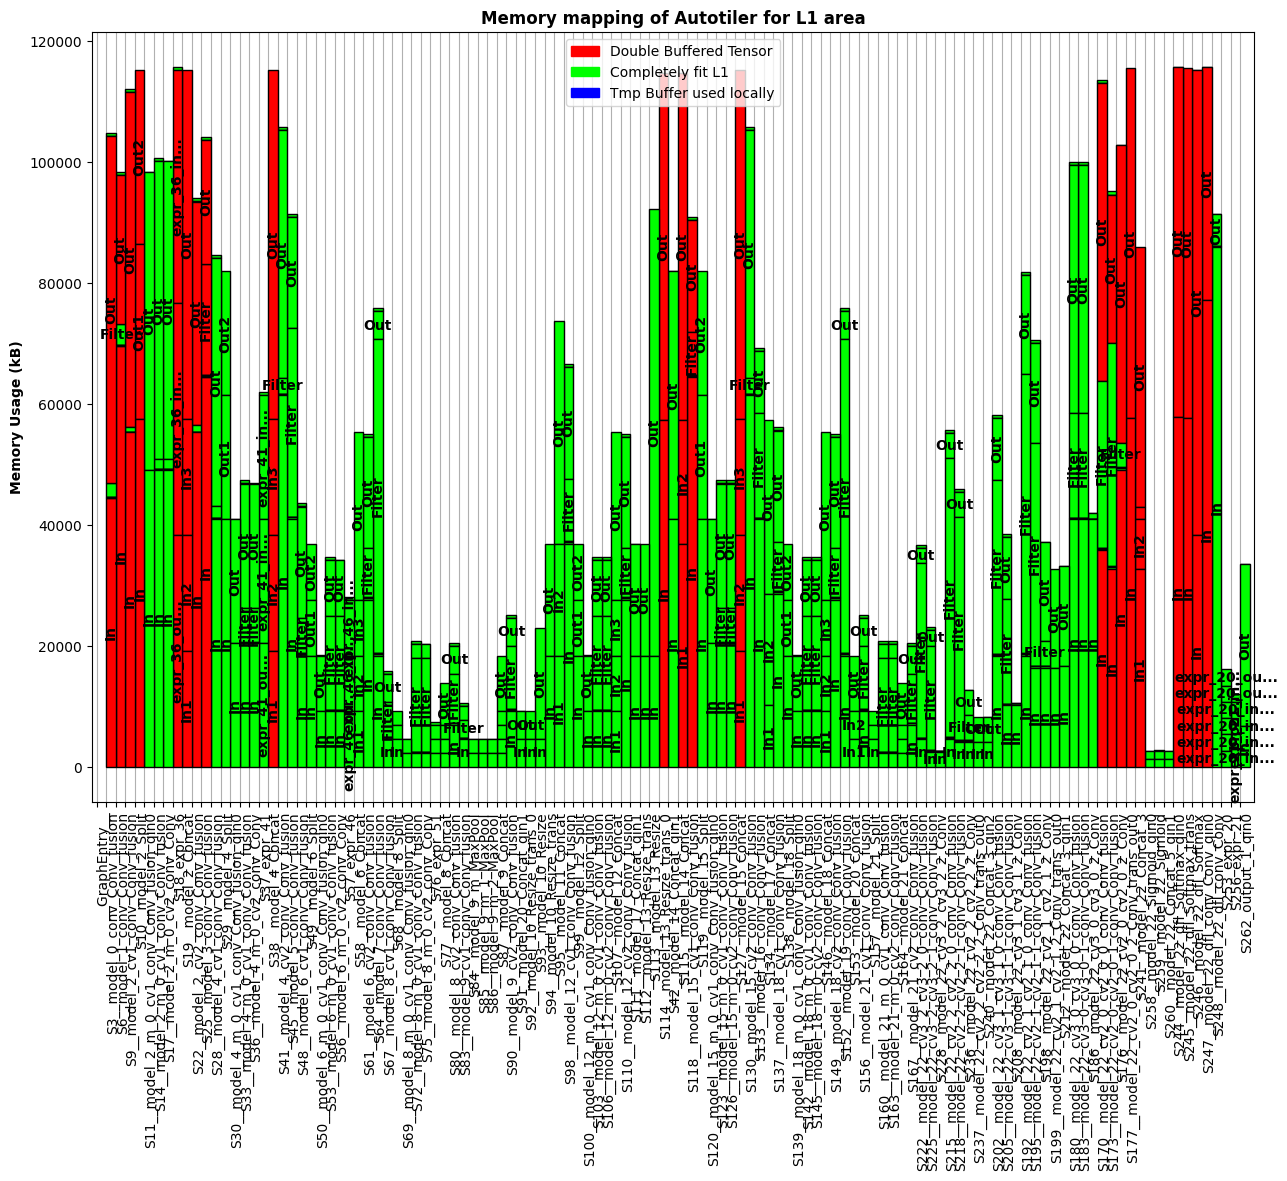

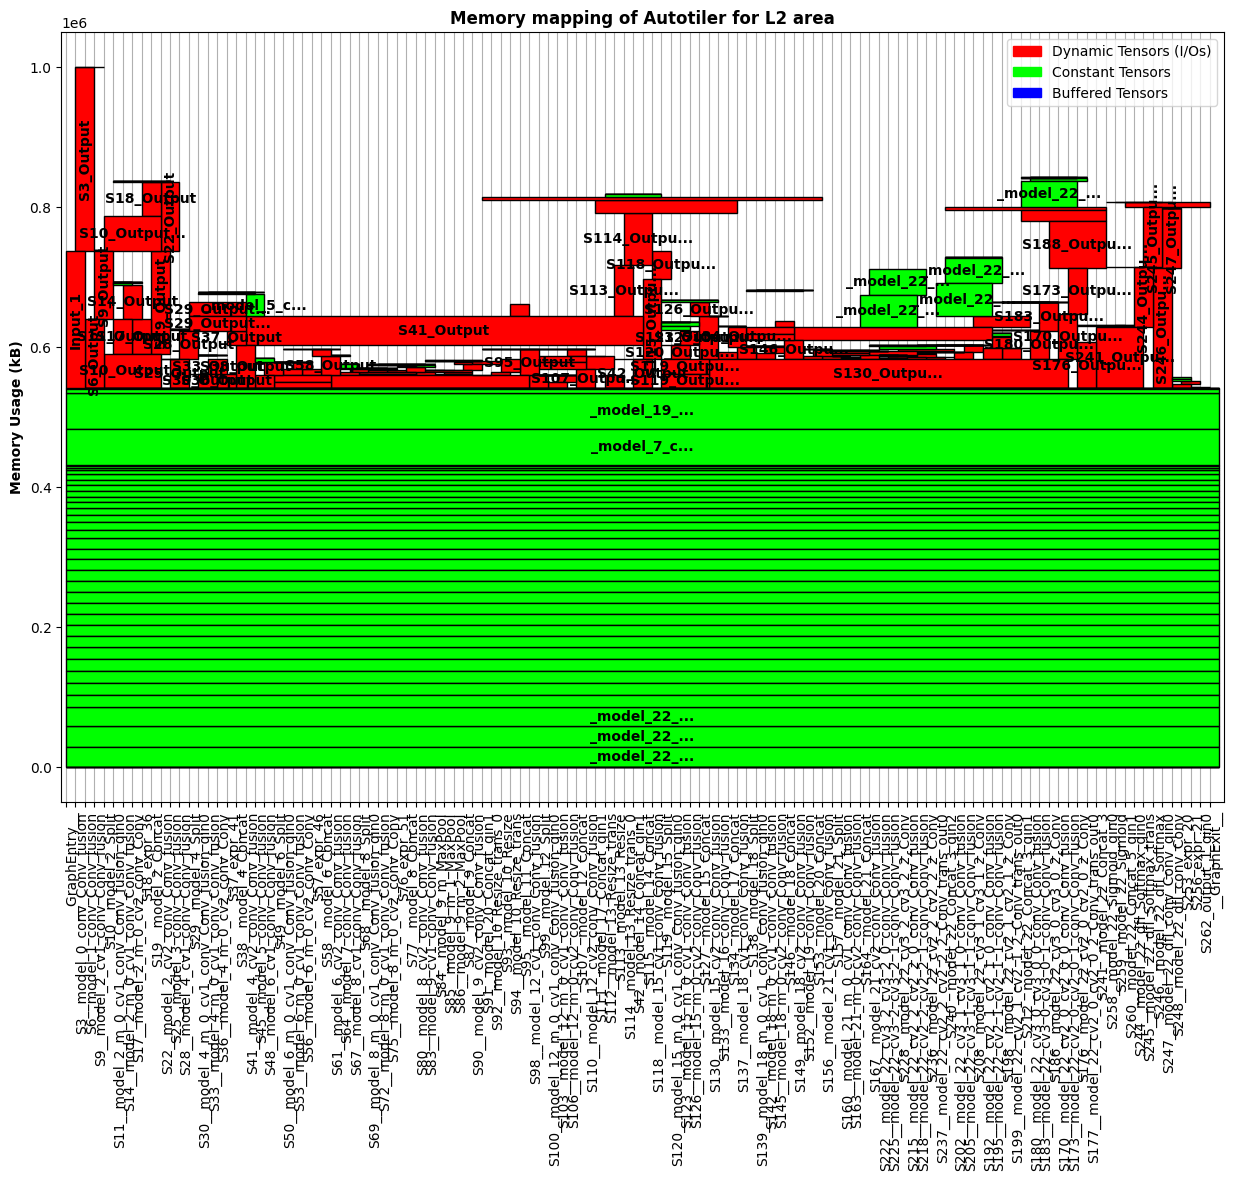

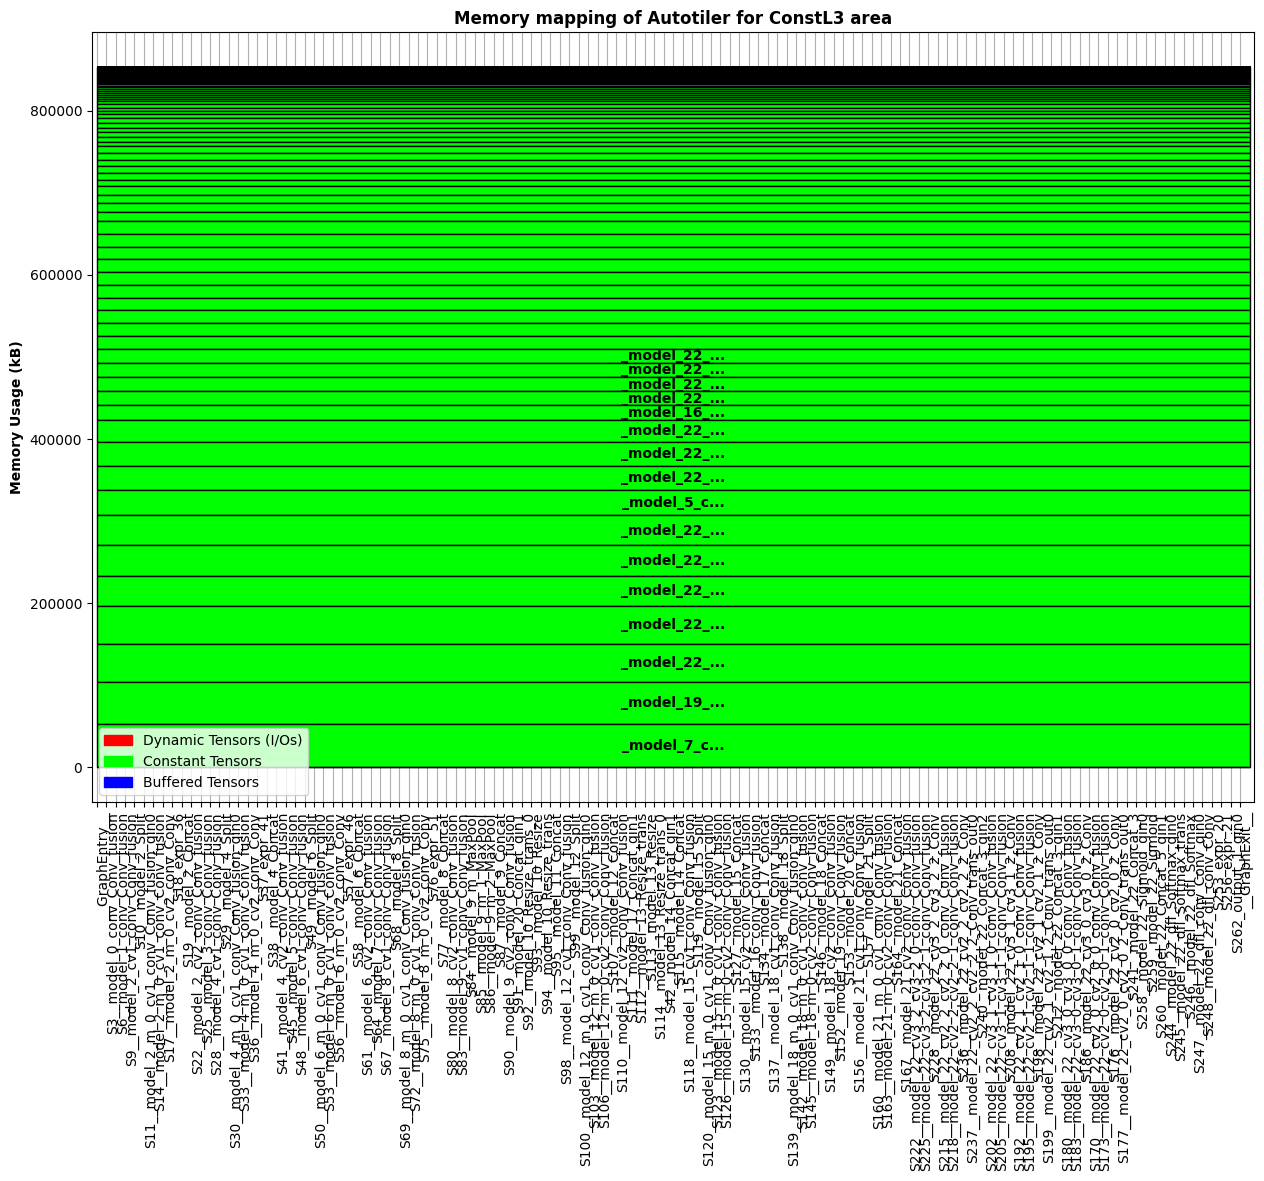

In [64]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (15,10)
res.plot_memory_boxes()

In [65]:
print("Out Name, QSNR NNTool vs Target run")
for outn in G.output_nodes():
    out_target = np.fromfile(f"{work_dir}/{outn.name.capitalize()}.bin", G.quantization[outn.name].in_qs[0].dtype)
    out_nntool = int_execution[G[outn.name].step_idx]
    print(f"{outn.name}, {G.qsnrs([out_target], [out_nntool[0].flatten()])}")
    print(out_nntool[0].flatten())
    print(out_target)

Out Name, QSNR NNTool vs Target run
output_1, (inf,)
[13.080832 19.621246 26.161663 ...  0.        0.        0.      ]
[13.080832 19.621246 26.161663 ...  0.        0.        0.      ]


In [166]:
import onnx

onnx_model = onnx.load('../../../ultralytics/runs/base-bee-working/weights/best.onnx')

In [144]:
concat_node = onnx_model.graph.node[-1]

In [145]:
sigmoid_node = onnx_model.graph.node[-2]

In [146]:
onnx_model.graph.node.remove(concat_node)
onnx_model.graph.node.remove(sigmoid_node)

In [147]:
output_node = onnx_model.graph.output[0]

In [148]:
mul_node = onnx_model.graph.node[-1]
mul_node

input: "/model.22/Concat_4_output_0"
input: "/model.22/Constant_12_output_0"
output: "/model.22/Mul_2_output_0"
name: "/model.22/Mul_2"
op_type: "Mul"

In [149]:
split_node = None
for node in onnx_model.graph.node:
    if node.name == "/model.22/Split":
        split_node = node
split_node

input: "/model.22/Concat_3_output_0"
input: "onnx::Split_365"
output: "/model.22/Split_output_0"
output: "/model.22/Split_output_1"
name: "/model.22/Split"
op_type: "Split"
attribute {
  name: "axis"
  i: 1
  type: INT
}

In [150]:
onnx_model.graph.output.remove(output_node)
# onnx_model.graph.output.extend([mul_node, split_node])

In [1]:
import onnx

onnx_model = onnx.load('../../../ultralytics/runs/base-pg2/weights/best.onnx')

inferred_model = onnx.shape_inference.infer_shapes(onnx_model)

inter_layers = ['/model.22/Split_output_1'] # output tensor names
value_info_protos = []
shape_info = onnx.shape_inference.infer_shapes(inferred_model)
for idx, node in enumerate(shape_info.graph.value_info):
    if node.name in inter_layers:
        print(idx, node)
        value_info_protos.append(node)
assert len(value_info_protos) == len(inter_layers)
inferred_model.graph.output.extend(value_info_protos)  #  in inference stage, these tensor will be added to output dict.

# inferred_model.graph.output[1].name = "output1"

onnx.checker.check_model(inferred_model, True)
onnx.save(inferred_model, '../../../ultralytics/runs/base-pg2/weights/best_upd.onnx')

221 name: "/model.22/Split_output_1"
type {
  tensor_type {
    elem_type: 1
    shape {
      dim {
        dim_value: 1
      }
      dim {
        dim_value: 1
      }
      dim {
        dim_value: 1344
      }
    }
  }
}



In [2]:
inferred_model.graph.output

[name: "output0"
type {
  tensor_type {
    elem_type: 1
    shape {
      dim {
        dim_value: 1
      }
      dim {
        dim_value: 5
      }
      dim {
        dim_value: 1344
      }
    }
  }
}
, name: "/model.22/Split_output_1"
type {
  tensor_type {
    elem_type: 1
    shape {
      dim {
        dim_value: 1
      }
      dim {
        dim_value: 1
      }
      dim {
        dim_value: 1344
      }
    }
  }
}
]